# Exploratory Data Analysis on Retail Sales Data

## 1. Introduction

Exploratory Data Analysis (EDA) is an important step in data analytics. It helps us understand a dataset, identify patterns, discover trends, and find useful business insights through statistical analysis and visualization.

In this project, we will analyze retail sales data using Python libraries such as Pandas, Matplotlib, and Seaborn.

## 2. Objectives

- Understand the structure and characteristics of the retail sales dataset.
- Identify missing values and check data quality.
- Calculate descriptive statistics for numerical columns.
- Analyze sales trends and product performance.
- Explore customer purchasing patterns using available data.
- Create visualizations to communicate findings.
- Provide actionable business recommendations based on the analysis.

## 3. Tools and Technologies

- Python
- Jupyter Notebook
- Pandas
- Matplotlib
- Seaborn

## 4. Dataset Description

The dataset contains retail transaction information, including product categories, customer details, quantities, dates, and sales totals. Additional simulated columns are included for educational analysis and will be clearly identified in the project.

In [1]:
# Import libraries for data analysis and visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display and chart style
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Retail Sales EDA project started successfully!")

Retail Sales EDA project started successfully!


In [2]:
# Load the retail sales dataset
df = pd.read_csv("Retail_Sales_Data_Enhanced.csv")

# Display the dataset dimensions
print("Number of rows and columns:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Display the first five rows
display(df.head())

Number of rows and columns: (1000, 19)

Column names:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating', 'Age_Simulated', 'Product_Name_Simulated']

Data types:
Invoice ID                  object
Branch                      object
City                        object
Customer type               object
Gender                      object
Product line                object
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total                      float64
Date                        object
Time                        object
Payment                     object
cogs                       float64
gross margin percentage    float64
gross income               float64
Rating                     float64
Age_Simulated                int64
Product_Name_Simulated      object
dtype: object

M

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating,Age_Simulated,Product_Name_Simulated
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,05-01-2019,13:08:00,Ewallet,522.83,4.761905,26.1415,9.1,22,Health and beauty Item 001
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,08-03-2019,10:29:00,Cash,76.40,4.761905,3.8200,9.6,55,Electronic accessories Item 001
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,03-03-2019,13:23:00,Credit card,324.31,4.761905,16.2155,7.4,49,Home and lifestyle Item 001
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,27-01-2019,20:33:00,Ewallet,465.76,4.761905,23.2880,8.4,39,Health and beauty Item 002
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,08-02-2019,10:37:00,Ewallet,604.17,4.761905,30.2085,5.3,38,Sports and travel Item 001


##  Data Cleaning

Data cleaning is an important step in data analysis. It helps identify missing values, duplicate records, and incorrect data types. In this section, we will check the quality of the dataset and prepare it for further analysis.

In [3]:
# Check the number of duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Check the data types of all columns
print("\nData types:")
print(df.dtypes)

# Display basic dataset information
print("\nDataset information:")
df.info()

Duplicate rows: 0

Missing values:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
Age_Simulated              0
Product_Name_Simulated     0
dtype: int64

Data types:
Invoice ID                  object
Branch                      object
City                        object
Customer type               object
Gender                      object
Product line                object
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total                      float64
Date                        object
Tim

In [4]:
# Convert the Date column to datetime format
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Check the converted data type
print("Date column data type:", df["Date"].dtype)

# Check invalid dates
print("Invalid dates:", df["Date"].isnull().sum())

Date column data type: datetime64[ns]
Invalid dates: 1000


In [5]:
# Display original date values from the dataset
df = pd.read_csv("Retail_Sales_Data_Enhanced.csv")

print("Sample date values:")
display(df["Date"].head(10))

Sample date values:


0    05-01-2019
1    08-03-2019
2    03-03-2019
3    27-01-2019
4    08-02-2019
5    25-03-2019
6    25-02-2019
7    24-02-2019
8    10-01-2019
9    20-02-2019
Name: Date, dtype: object

In [6]:
# Convert dates using automatic format detection
df["Date"] = pd.to_datetime(
    df["Date"],
    format="mixed",
    dayfirst=False,
    errors="coerce"
)

# Verify the conversion
print("Date data type:", df["Date"].dtype)
print("Invalid dates:", df["Date"].isnull().sum())

display(df[["Date"]].head(10))

Date data type: datetime64[ns]
Invalid dates: 0


,Date
0,2019-05-01
1,2019-08-03
2,2019-03-03
3,2019-01-27
4,2019-08-02
5,2019-03-25
6,2019-02-25
7,2019-02-24
8,2019-10-01
9,2019-02-20


##  Descriptive Statistical Analysis

Descriptive statistics help us understand the main characteristics of numerical data. In this section, we calculate the mean, median, mode, and standard deviation to summarize sales, quantity, prices, ratings, and other numerical variables.

In [7]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Display basic descriptive statistics
print("Descriptive Statistics:")
display(numeric_df.describe().T.round(2))

# Calculate mean, median, mode, and standard deviation
statistics = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median(),
    "Mode": numeric_df.mode().iloc[0],
    "Standard Deviation": numeric_df.std()
})

print("Detailed Statistical Summary:")
display(statistics.round(2))

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Unit price,1000.0,55.67,26.49,10.08,32.88,55.23,77.94,99.96
Quantity,1000.0,5.51,2.92,1.00,3.00,5.00,8.00,10.00
Tax 5%,1000.0,15.38,11.71,0.51,5.92,12.09,22.45,49.65
Total,1000.0,322.97,245.89,10.68,124.42,253.85,471.35,1042.65
cogs,1000.0,307.59,234.18,10.17,118.50,241.76,448.90,993.00
gross margin percentage,1000.0,4.76,0.00,4.76,4.76,4.76,4.76,4.76
gross income,1000.0,15.38,11.71,0.51,5.92,12.09,22.45,49.65
Rating,1000.0,6.97,1.72,4.00,5.50,7.00,8.50,10.00
Age_Simulated,1000.0,41.65,13.85,18.00,29.00,42.00,54.00,65.00


Detailed Statistical Summary:


,Mean,Median,Mode,Standard Deviation
Unit price,55.67,55.23,83.77,26.49
Quantity,5.51,5.00,10.00,2.92
Tax 5%,15.38,12.09,4.15,11.71
Total,322.97,253.85,87.23,245.89
cogs,307.59,241.76,83.08,234.18
gross margin percentage,4.76,4.76,4.76,0.00
gross income,15.38,12.09,4.15,11.71
Rating,6.97,7.00,6.00,1.72
Age_Simulated,41.65,42.00,22.00,13.85


##  Monthly Sales Analysis

Monthly sales analysis helps us understand how sales change over time. We will group the sales data by month and visualize the monthly sales trends using a line chart.

In [8]:
# Extract the month from the Date column
df["Month"] = df["Date"].dt.to_period("M")

# Calculate total sales for each month
monthly_sales = df.groupby("Month")["Total"].sum()

# Display monthly sales
display(monthly_sales)

Month
2019-01    86562.5670
2019-02    63169.7430
2019-03    72749.2500
2019-04     7957.6245
2019-05    12798.6915
2019-06     9612.2250
2019-07    11500.7130
2019-08    13503.7770
2019-09    13767.2850
2019-10     9865.2015
2019-11     9618.3675
2019-12    11861.3040
Freq: M, Name: Total, dtype: float64

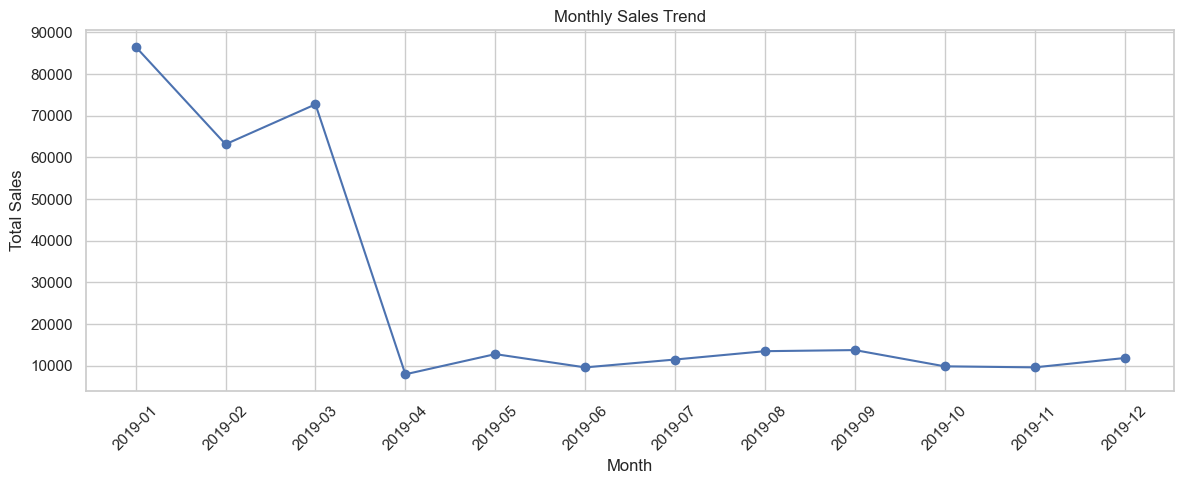

In [9]:
# Create a line chart for monthly sales
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation

The line chart shows how total sales vary across different months. Peaks indicate months with higher sales, while dips indicate months with lower sales. The chart can help identify seasonal patterns and changes in business performance.

The specific months with the highest and lowest sales will be identified from the actual chart.

## Product Line-wise Sales Analysis

Product line analysis helps us compare the sales performance of different product categories. In this section, we calculate total sales for each product line and visualize the results using a bar chart.

In [10]:
# Calculate total sales for each product line
product_sales = (
    df.groupby("Product line")["Total"]
    .sum()
    .sort_values(ascending=False)
)

# Display product line sales
display(product_sales)

Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Total, dtype: float64

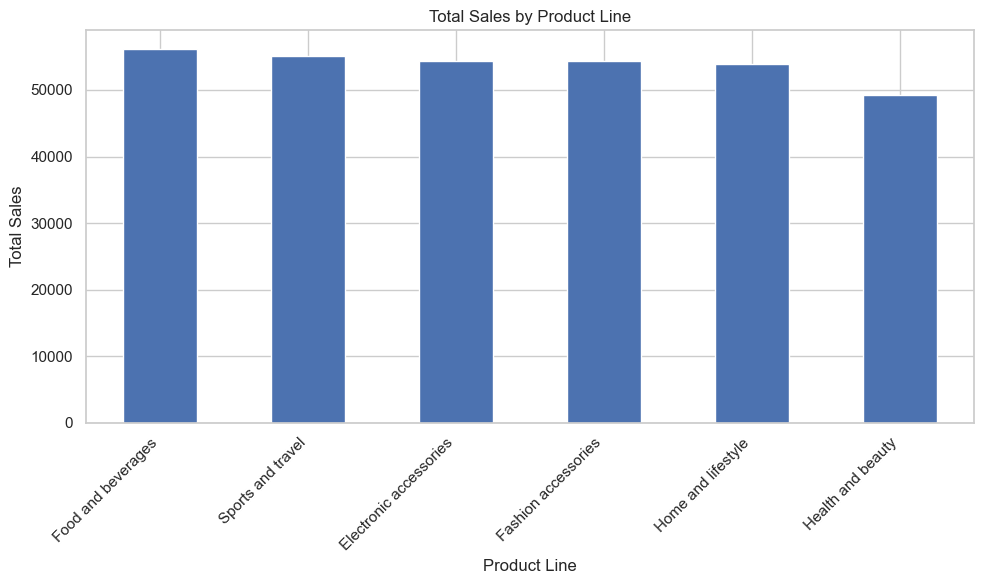

In [11]:
# Create a bar chart of sales by product line
plt.figure(figsize=(10, 6))

product_sales.plot(kind="bar")

plt.title("Total Sales by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Observation

The bar chart compares total sales across different product lines. Product lines with higher bars contribute more to total sales, while those with lower bars contribute less. These results can help the business identify its strongest product categories and areas that may need improvement.

## 13. Customer Gender Analysis

Customer gender analysis helps us compare purchasing activity across customer groups. In this section, we will calculate total sales by gender and visualize the comparison using a bar chart.

In [12]:
# Calculate total sales by gender
gender_sales = df.groupby("Gender")["Total"].sum()

# Display the results
display(gender_sales)

Gender
Female    167882.925
Male      155083.824
Name: Total, dtype: float64

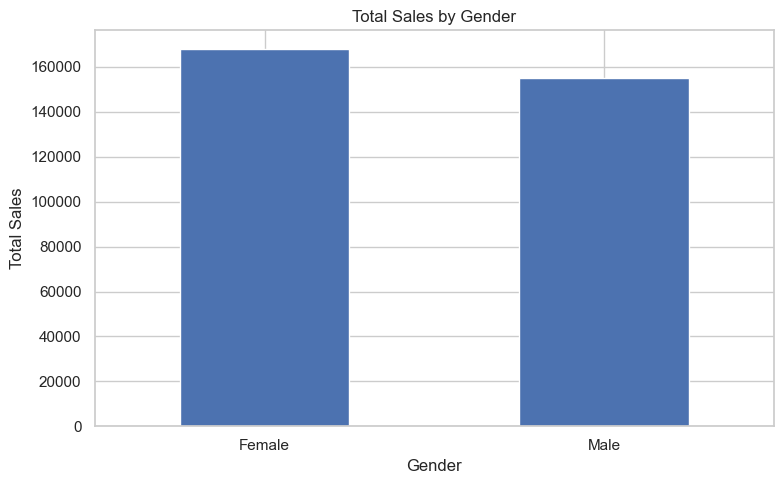

In [13]:
# Create a bar chart of sales by gender
plt.figure(figsize=(8, 5))

gender_sales.plot(kind="bar")

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation

The bar chart compares total sales across gender groups. The group with the higher bar contributes more to total sales in this dataset. This comparison describes the available transactions and does not necessarily represent overall customer preferences.

In [14]:
# Calculate total sales by age
age_sales = df.groupby("Age_Simulated")["Total"].sum()

# Display the results
display(age_sales)

Age_Simulated
18     5873.8785
19     5985.0315
20     5495.0910
21     3786.6570
22    10069.5945
23     5799.2550
24     9008.1705
25     8916.2010
26     6827.3940
27     5700.0405
28     3160.0275
29     9016.5390
30     4924.3005
31     5664.7920
32     6129.7530
33     5885.3970
34     3610.4145
35     5867.4210
36     3603.8835
37     6298.9185
38     8726.4975
39     8180.8440
40     8873.9385
41     5635.1610
42     9127.6290
43     6273.3195
44     9386.3910
45     6450.9060
46     6485.7135
47     6558.3210
48     7199.3040
49     7792.3125
50     7142.9085
51     5004.2475
52     7400.6205
53     9237.5325
54     4706.1630
55    11832.8805
56     8217.3210
57     8099.9205
58     6419.7840
59     4682.1075
60     6218.2260
61     4989.3165
62     8441.7060
63     5800.6515
64     6009.2550
65     6451.0110
Name: Total, dtype: float64

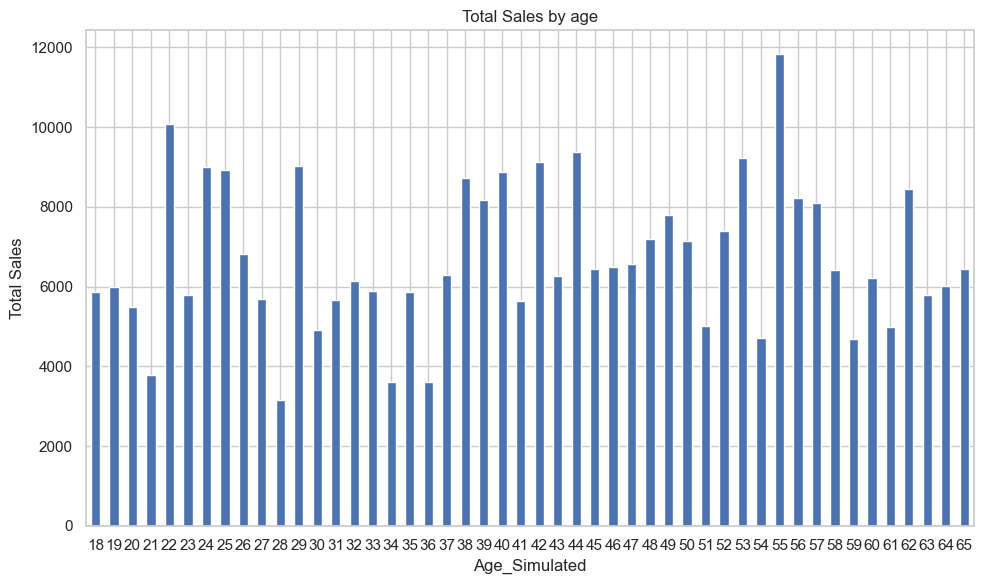

In [15]:
plt.figure(figsize=(10, 6))

age_sales.plot(kind="bar")

plt.title("Total Sales by age")
plt.xlabel("Age_Simulated")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##  Customer Type Analysis

Customer type analysis helps us compare purchasing activity between members and normal customers. This analysis can help the business understand how its membership customers contribute to total sales.

In [16]:
# Calculate total sales by customer type
customer_type_sales = df.groupby("Customer type")["Total"].sum()

# Sort sales from highest to lowest
customer_type_sales = customer_type_sales.sort_values(ascending=False)

# Display the results
display(customer_type_sales)

Customer type
Member    164223.444
Normal    158743.305
Name: Total, dtype: float64

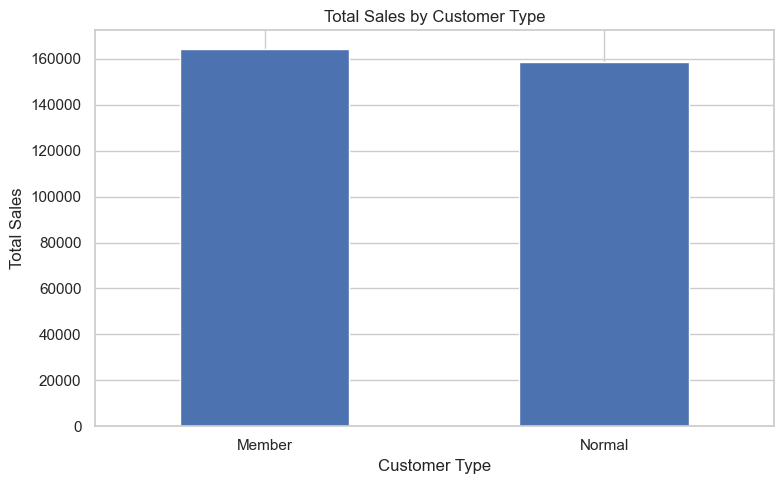

In [17]:
# Create a bar chart of sales by customer type
plt.figure(figsize=(8, 5))

customer_type_sales.plot(kind="bar")

plt.title("Total Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation

The bar chart compares total sales generated by member and normal customers. The customer group with the higher bar contributes more to total sales in this dataset. These findings can help the business evaluate its membership strategy and identify opportunities to improve customer engagement.

##  Best-Selling Product Lines Analysis

This analysis identifies product lines with the highest total quantities sold. Understanding product demand can help businesses manage inventory, plan promotions, and improve product availability.

In [18]:
# Calculate total quantity sold for each product line
top_products = (
    df.groupby("Product line")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Display the top product lines
display(top_products)

Product line
Electronic accessories    971
Food and beverages        952
Sports and travel         920
Home and lifestyle        911
Fashion accessories       902
Health and beauty         854
Name: Quantity, dtype: int64

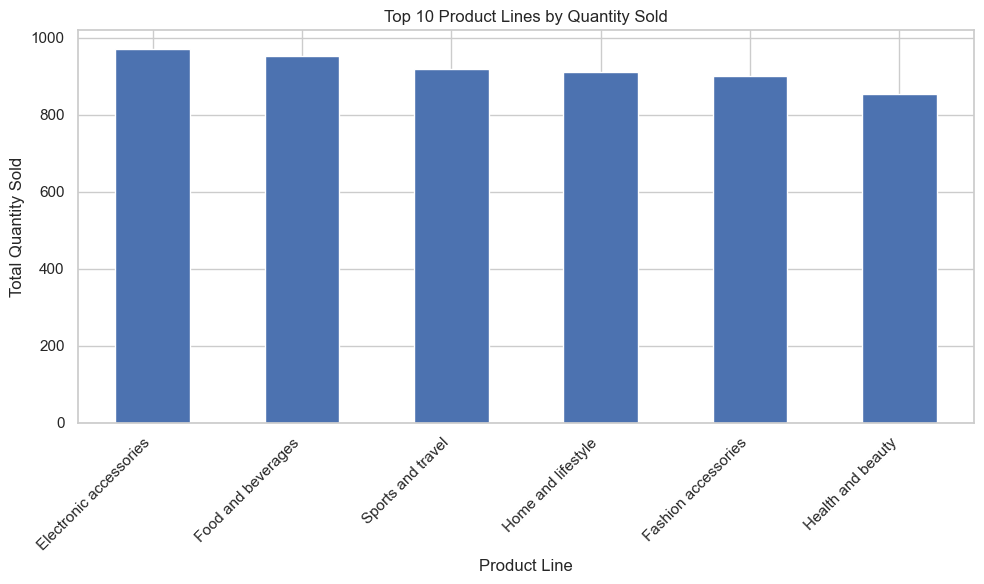

In [19]:
# Visualize the top-selling product lines
plt.figure(figsize=(10, 6))

top_products.plot(kind="bar")

plt.title("Top 10 Product Lines by Quantity Sold")
plt.xlabel("Product Line")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Observation

The bar chart compares product lines based on total quantity sold. Product lines with higher bars have greater sales volume in terms of quantity. These findings can help businesses prioritize inventory and identify categories that may benefit from promotional activities.

##  Revenue Analysis by Product Line

Revenue analysis helps us understand how much sales value each product line generates. In this section, we calculate the total sales for each product line and compare their performance using a bar chart.

In [20]:
# Calculate total sales for each product line
revenue_by_product = (
    df.groupby("Product line")["Total"]
    .sum()
    .sort_values(ascending=False)
)

# Display the results
display(revenue_by_product)

Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Total, dtype: float64

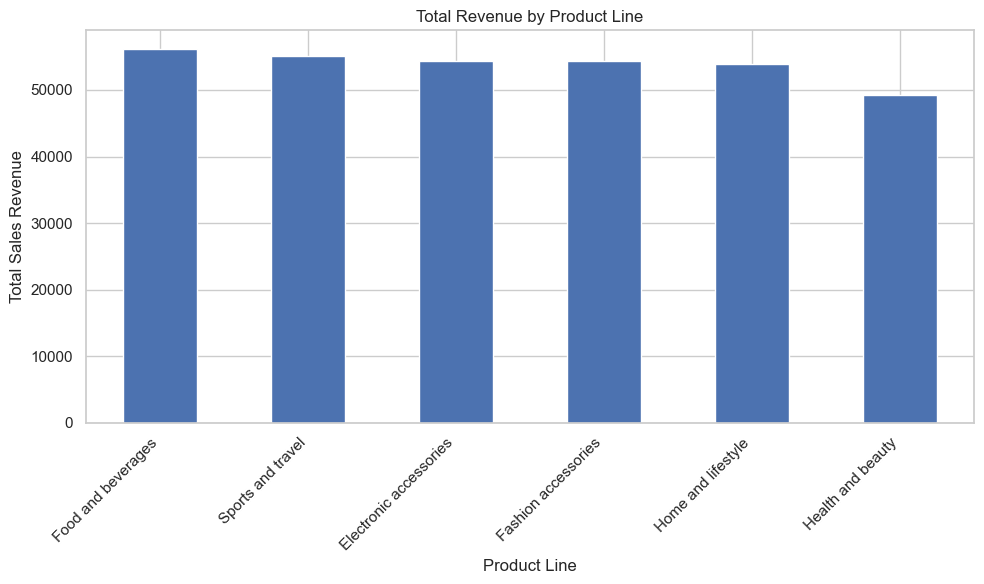

In [21]:
# Create a bar chart of revenue by product line
plt.figure(figsize=(10, 6))

revenue_by_product.plot(kind="bar")

plt.title("Total Revenue by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Sales Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Observation

The bar chart compares total sales revenue across product lines. Categories with higher bars generate more sales value, while categories with lower bars generate less. These findings can help the business identify its major revenue-generating categories and plan future sales strategies.

## Correlation Heatmap

Correlation analysis helps us understand the strength and direction of linear relationships between numerical variables. In this section, we use a correlation matrix and a heatmap to visualize these relationships and identify patterns in the retail sales data.

In [22]:
# Select numerical columns from the dataset
numeric_df = df.select_dtypes(include="number")

# Calculate the correlation matrix
correlation_matrix = numeric_df.corr()

# Display the correlation values
display(correlation_matrix.round(2))

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating,Age_Simulated
Unit price,1.00,0.01,0.63,0.63,0.63,NaN,0.63,-0.01,0.03
Quantity,0.01,1.00,0.71,0.71,0.71,NaN,0.71,-0.02,0.01
Tax 5%,0.63,0.71,1.00,1.00,1.00,NaN,1.00,-0.04,0.03
Total,0.63,0.71,1.00,1.00,1.00,NaN,1.00,-0.04,0.03
cogs,0.63,0.71,1.00,1.00,1.00,NaN,1.00,-0.04,0.03
gross margin percentage,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gross income,0.63,0.71,1.00,1.00,1.00,NaN,1.00,-0.04,0.03
Rating,-0.01,-0.02,-0.04,-0.04,-0.04,NaN,-0.04,1.00,0.00
Age_Simulated,0.03,0.01,0.03,0.03,0.03,NaN,0.03,0.00,1.00


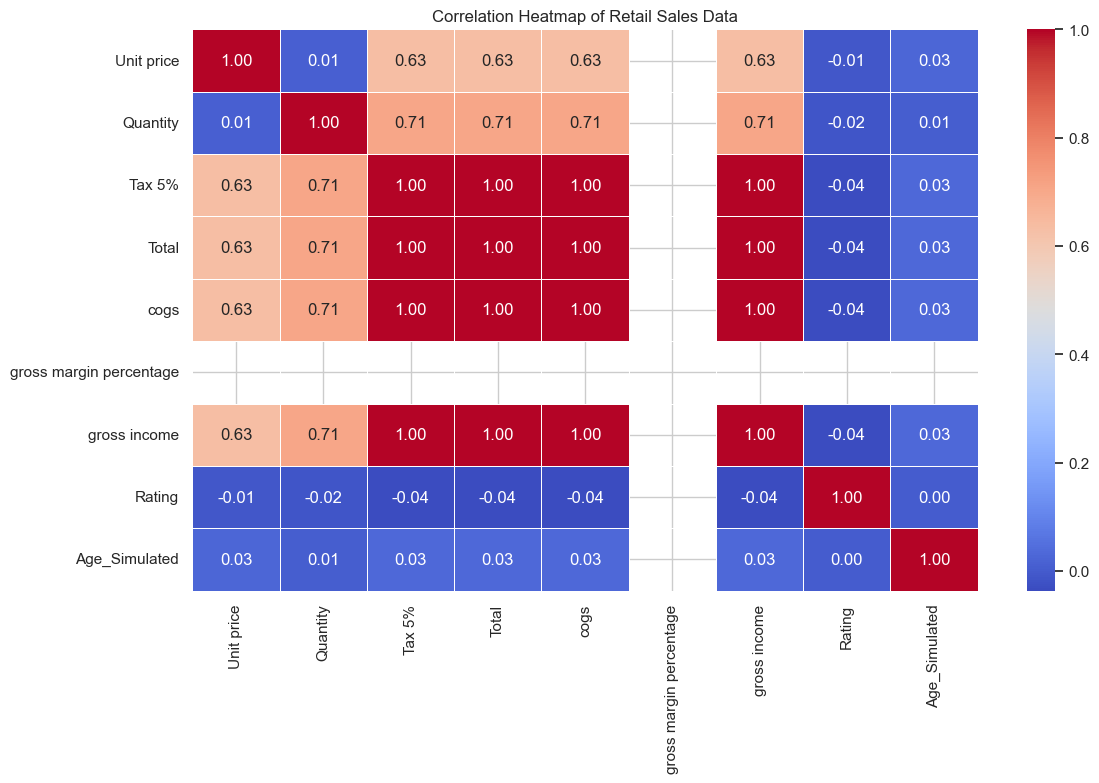

In [23]:
# Create a correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Retail Sales Data")
plt.tight_layout()
plt.show()

### Interpretation

The correlation heatmap shows the direction and strength of linear relationships among numerical variables.

- Values closer to +1 indicate stronger positive linear relationships.
- Values closer to -1 indicate stronger negative linear relationships.
- Values closer to 0 indicate weaker linear relationships.

The actual relationships will be interpreted from the generated heatmap. Correlation does not necessarily imply causation.

## Additional Analysis: Payment Method

This analysis examines the distribution of payment methods and compares the total sales generated by each payment method. It helps us understand how customers pay for their purchases.

In [24]:
# Calculate total sales for each payment method
payment_sales = df.groupby("Payment")["Total"].sum()

# Sort sales from highest to lowest
payment_sales = payment_sales.sort_values(ascending=False)

# Display the results
display(payment_sales)

Payment
Cash           112206.570
Ewallet        109993.107
Credit card    100767.072
Name: Total, dtype: float64

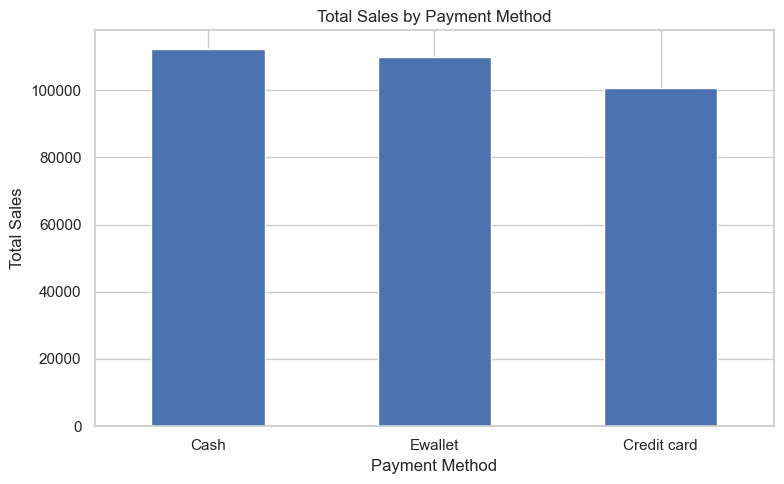

In [25]:
# Create a bar chart of sales by payment method
plt.figure(figsize=(8, 5))
payment_sales.plot(kind="bar")

plt.title("Total Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Observations: Sales by Payment Method

1. Cash generated the highest total sales among the three payment methods.
2. Ewallet sales were slightly lower than Cash sales.
3. Credit card generated the lowest total sales in this dataset.
4. The sales amounts across the three payment methods were relatively close.
5. The business can analyze both transaction counts and average transaction values to better understand customer payment preferences.

**Conclusion:** Cash contributed the highest total sales in this dataset, but further analysis is needed to understand customer payment behaviour.

In [26]:
# Count transactions for each payment method
payment_counts = df["Payment"].value_counts()

# Calculate average transaction value for each payment method
average_payment = df.groupby("Payment")["Total"].mean()

# Combine the results into one table
payment_analysis = pd.DataFrame({
    "Transaction Count": payment_counts,
    "Total Sales": payment_sales,
    "Average Transaction Value": average_payment
})

display(payment_analysis.round(2))

,Transaction Count,Total Sales,Average Transaction Value
Payment,,,
Cash,344,112206.57,326.18
Credit card,311,100767.07,324.01
Ewallet,345,109993.11,318.82


### Observations: Payment Method Analysis

1. Cash generated the highest total sales of 112,206.57 across 344 transactions.
2. Ewallet had the highest transaction count, with 345 transactions.
3. Credit card had the lowest transaction count, with 311 transactions, and the lowest total sales of 100,767.07.
4. Cash had the highest average transaction value of 326.18, while Ewallet had an average transaction value of 318.82.
5. Cash generated higher total sales than Ewallet despite having one fewer transaction, partly because its average transaction value was higher.

**Business Recommendation:** The business can monitor average transaction values and transaction counts for each payment method to better understand sales patterns.

# Final Conclusion

## Project Summary

In this project, Exploratory Data Analysis (EDA) was performed on retail sales data using Python, Pandas, Matplotlib, and Seaborn. The dataset was inspected, numerical summaries were generated, and visualizations were created to understand sales patterns and customer transactions.

## Key Findings

1. **Sales Trends:** Monthly sales were analyzed to identify changes in sales over time.
2. **Product Line Analysis:** Sales and quantities were compared across product categories to identify better-performing categories.
3. **Customer Analysis:** Sales were compared by gender and customer type to understand differences between customer groups.
4. **Correlation Analysis:** Quantity showed a positive correlation with Total sales (0.71). Rating had almost no linear correlation with Total sales (-0.04).
5. **Payment Method Analysis:** Cash generated the highest total sales (112,206.57), while Ewallet had the highest transaction count (345). Cash also had the highest average transaction value (326.18).

## Business Recommendations

1. **Monitor Product Performance:** Track sales and quantities by product line to support inventory and promotion decisions.
2. **Review Monthly Sales:** Compare high- and low-sales months to help plan inventory and marketing activities.
3. **Analyze Payment Behaviour:** Monitor transaction counts and average transaction values for each payment method.
4. **Improve Customer Insights:** Collect reliable customer data to better understand purchasing patterns and customer satisfaction.
5. **Use Data-Driven Decisions:** Regularly review sales reports and visualizations to identify opportunities for improvement.

## Limitations

The Age_Simulated column contains simulated values rather than actual customer ages. Therefore, it cannot be used to draw conclusions about real customer age groups. Correlation shows association and does not establish causation.

## Conclusion

This project demonstrates how Python-based EDA can help summarize retail data, visualize sales patterns, compare product categories, and identify relationships between numerical variables. The findings can support further investigation and more informed retail business decisions.